In [1]:
import pathlib
import sys

import numpy as np
from matplotlib import pyplot as plt

# the analysis code lives in epg_across_dark_analysis.py next to this notebook
sys.path.insert(0, str(pathlib.Path.cwd()))
import epg_across_dark_analysis as ana

import el_hd_plasticity.two_photon as nmp

plt.rcParams['pdf.fonttype'] = 42

%load_ext autoreload
%autoreload 2
%matplotlib inline

# How far the neural phase lags the behavior

The population vector angle follows the fly's heading, but the indicator reports it late. To measure by how much,
the angular velocity of the PVA is correlated with the angular velocity of the heading while the neural trace is
slid in time; the lag of the largest correlation is how far the neural signal trails the behavior.

`SessionTimeseries.from_session` corrects for this with its `neural_shift` argument, so the timeseries here are
built with `neural_shift=0` (the default of `stats.lag_stats`) -- otherwise the correction would already have
removed the lag being measured.

Only the EPG-across-dark sessions are analysed for now; the other datasets of the original notebook reach the
same statistic through `nmp.stats.lag_stats` with their own session manager.

In [2]:
sess_manager = ana.load_session_manager()     # folders: see ana.DEFAULT_BASEDIR, ana.DEFAULT_FIGDIR
print(f'{sess_manager.sess_df["fly_id"].nunique()} flies, {len(sess_manager.sess_df)} sessions')
print(f'lags (s): {ana.LAGS[0]:.1f} to {ana.LAGS[-1]:.1f}, the shift applied by default: {ana.NEURAL_SHIFT}')

14 flies, 41 sessions
lags (s): -1.0 to 1.0, the shift applied by default: -0.2


## The lag curves

Left: closed loop against dark, mean +- SEM over flies. Right: every session pooled. The dashed line is the
`neural_shift` the codebase applies; the peak of the curve is what it should be.

{'n_flies': 14,
 'n_sessions': 41,
 'peak_lag_all': -0.2,
 'peak_lag_per_fly_median': -0.2,
 'peak_lag_per_fly_range': [-0.4, -0.2],
 'applied_neural_shift': -0.2,
 'peak_lag_closed_loop': -0.3,
 'peak_lag_dark': -0.2}

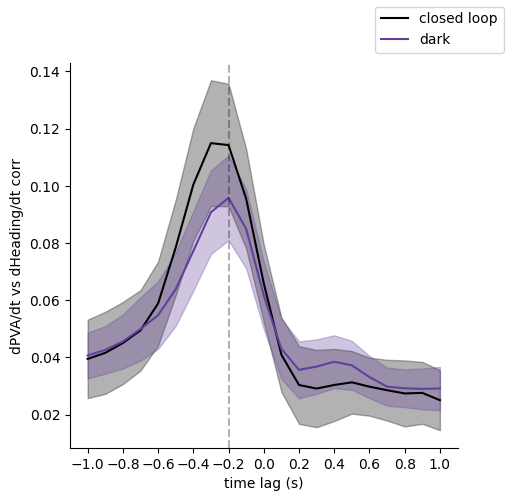

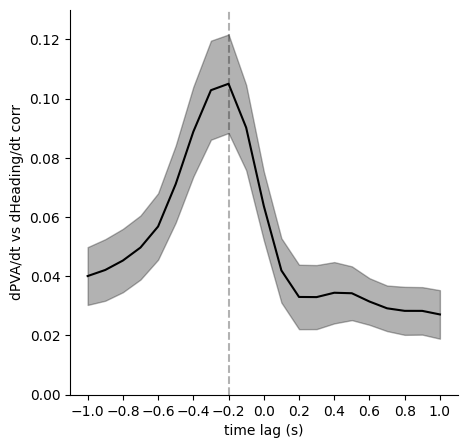

In [5]:
(fig_by_condition, fig_all), lag_summary = ana.plot_phase_lag(sess_manager)
lag_summary

## Per-session and per-fly lags

The curve of every session, and the lag of its peak, to see how consistent the estimate is across sessions.

In [4]:
lag_stats = nmp.stats.lag_stats(sess_manager, meta_cols=ana.META_COLS, lags=ana.LAGS)
lag_stats['peak_lag'] = nmp.stats.peak_lag(np.stack(lag_stats['xcorr']), ana.LAGS)
lag_stats[['fly_id', 'closed_loop', 'peak_lag']]

,fly_id,closed_loop,peak_lag
0,06_01_2025_fly1_condition_control,1,-0.2
1,06_01_2025_fly1_condition_control,0,-0.2
2,06_01_2025_fly1_condition_control,2,0.0
3,06_01_2025_fly2_condition_control,1,-0.2
4,06_01_2025_fly2_condition_control,0,0.0
5,06_01_2025_fly2_condition_control,2,-0.2
6,07_01_2025_fly1_condition_control,1,-0.3
7,07_01_2025_fly1_condition_control,0,-0.1
8,07_01_2025_fly1_condition_control,2,-0.3
9,07_01_2025_fly2_condition_control,1,-0.3


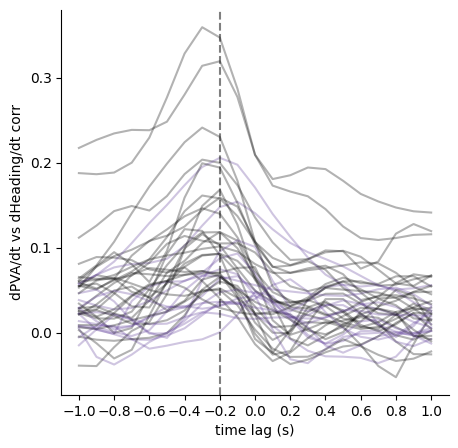

In [5]:
fig, ax = plt.subplots(figsize=[5, 5])
for _, row in lag_stats.iterrows():
    ax.plot(ana.LAGS, row['xcorr'], color=ana.CL_COLOR if row['closed_loop'] else ana.DARK_COLOR, alpha=.3)
ax.axvline(ana.NEURAL_SHIFT, color='k', linestyle='--', alpha=.5)
ax.set_xticks(ana.LAGS[::2])
ax.set_xlabel('time lag (s)')
ax.set_ylabel('dPVA/dt vs dHeading/dt corr')
nmp.plotting.despine(ax)
fig.savefig(sess_manager.fig_folder / 'xcorr_sessions.pdf', bbox_inches='tight')

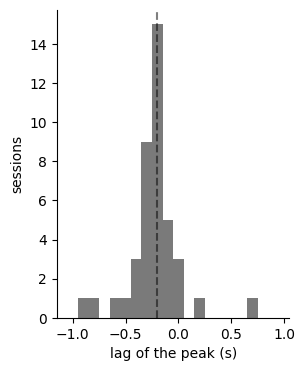

In [6]:
fig, ax = plt.subplots(figsize=[3, 4])
ax.hist(lag_stats['peak_lag'], bins=ana.LAGS - np.diff(ana.LAGS)[0] / 2, color=plt.cm.Greys(.6))
ax.axvline(ana.NEURAL_SHIFT, color='k', linestyle='--', alpha=.5)
ax.set_xlabel('lag of the peak (s)')
ax.set_ylabel('sessions')
nmp.plotting.despine(ax)
fig.savefig(sess_manager.fig_folder / 'xcorr_peak_lag_hist.pdf', bbox_inches='tight')